In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [ ]:

mob_model = load_model('models/MobileNetV2/model_224.keras')
resnet_model = load_model('models/ResNet50/model_224.keras')
inception_model = load_model('models/InceptionV3/model_224.keras')
eff_model = load_model('models/EfficientNetB1/model_224.keras')


In [ ]:

test_datagen = ImageDataGenerator(preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input)

test_images = test_datagen.flow_from_directory(
    './test_images',  
    target_size=(224, 224),  
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

Found 864 images belonging to 5 classes.


In [10]:
def evaluate_model(model, model_name):
    print(f"Evaluating {model_name}...")

    results = model.evaluate(test_images, verbose=1)
    test_accuracy = results[1]

    print(f"{model_name} - Test Accuracy: {test_accuracy:.4f}")
    print("-" * 50)

In [ ]:

evaluate_model(eff_model, 'EfficientNetB1')
evaluate_model(mob_model, 'MobileNetV2')
evaluate_model(inception_model, 'InceptionV3')
evaluate_model(resnet_model, 'ResNet50')

Evaluating EfficientNetB1...
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 226ms/step - AUC: 0.9926 - accuracy: 0.9902 - loss: 0.0340
EfficientNetB1 - Test Accuracy: 0.9850
--------------------------------------------------
Evaluating MobileNetV2...
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - AUC: 0.9876 - accuracy: 0.9197 - loss: 0.2737
MobileNetV2 - Test Accuracy: 0.9201
--------------------------------------------------
Evaluating InceptionV3...
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 252ms/step - AUC: 0.9843 - accuracy: 0.9105 - loss: 0.2453
InceptionV3 - Test Accuracy: 0.9155
--------------------------------------------------
Evaluating ResNet50...
27/27 ━━━━━━━━━━━━━━━━━━━━ 12s 434ms/step - AUC: 0.9712 - accuracy: 0.8847 - loss: 0.3143
ResNet50 - Test Accuracy: 0.8762
--------------------------------------------------


In [ ]:
import random

def visualize_predictions(model, test_generator, class_labels, model_name, num_images=10):
    test_generator.reset()
    batch_images, batch_labels = next(test_generator)

    num_images = min(num_images, len(batch_images))

    indices = random.sample(range(len(batch_images)), num_images)
    selected_images = batch_images[indices]
    selected_labels = batch_labels[indices]

    predictions = model.predict(selected_images)
    predicted_classes = np.argmax(predictions, axis=1)
    true_classes = np.argmax(selected_labels, axis=1)

    plt.figure(figsize=(18, 7))
    for i in range(num_images):
        plt.subplot(2, 5, i + 1)
        plt.imshow(selected_images[i])
        plt.title(
            f"Pred: {class_labels[predicted_classes[i]]}\nActual: {class_labels[true_classes[i]]}",
            fontsize=10
        )
        plt.axis('off')

    plt.suptitle(f"{model_name} - Predictions", fontsize=18)
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)  
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..

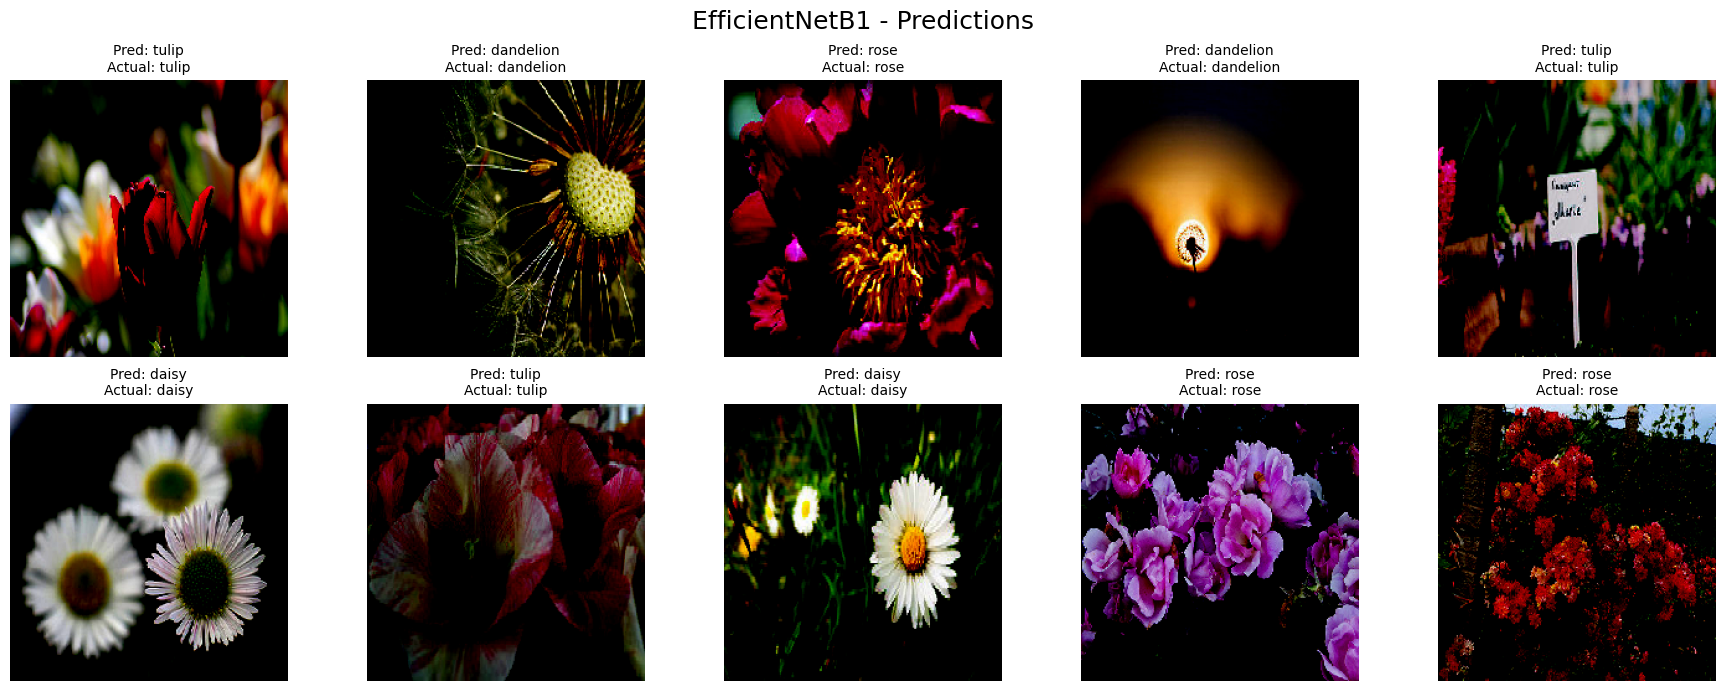

In [36]:
class_labels = list(test_images.class_indices.keys())

visualize_predictions(eff_model, test_images, class_labels, 'EfficientNetB1')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


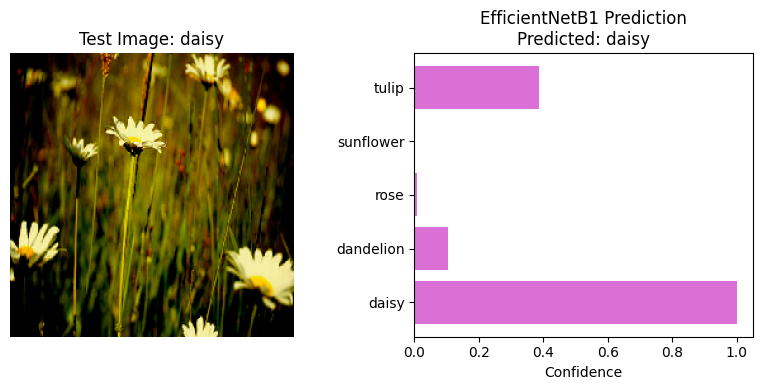

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


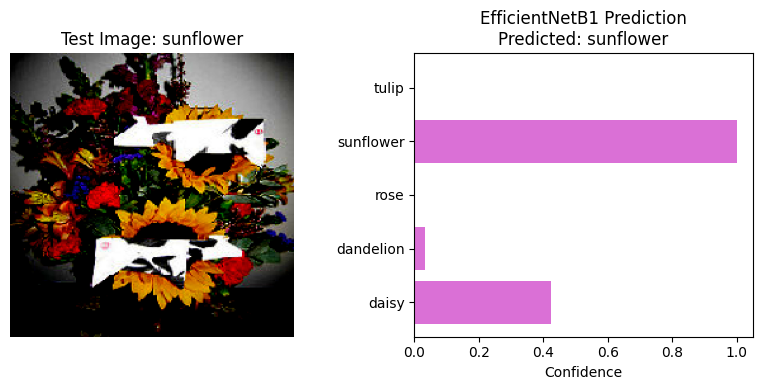

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


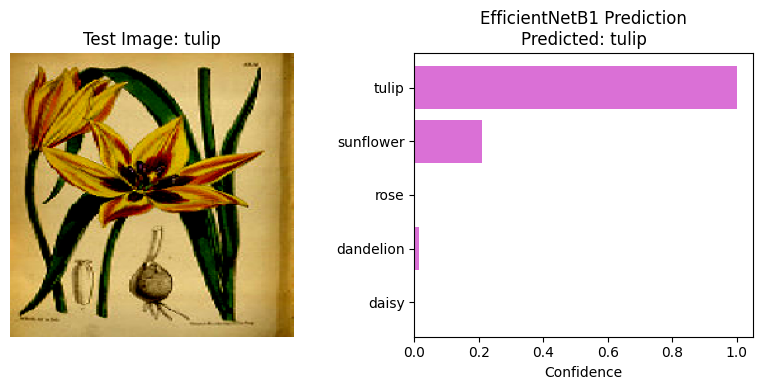

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


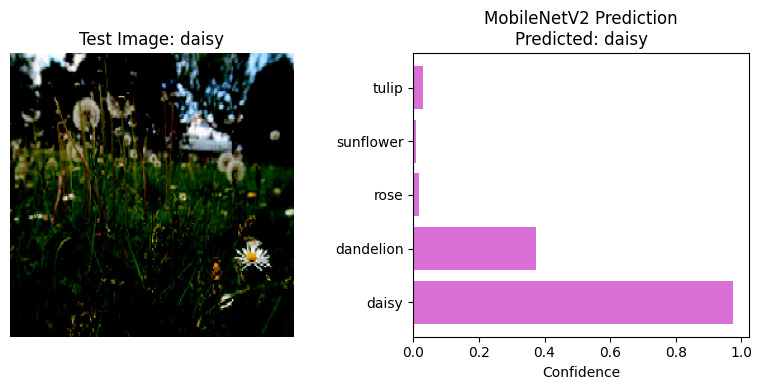

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


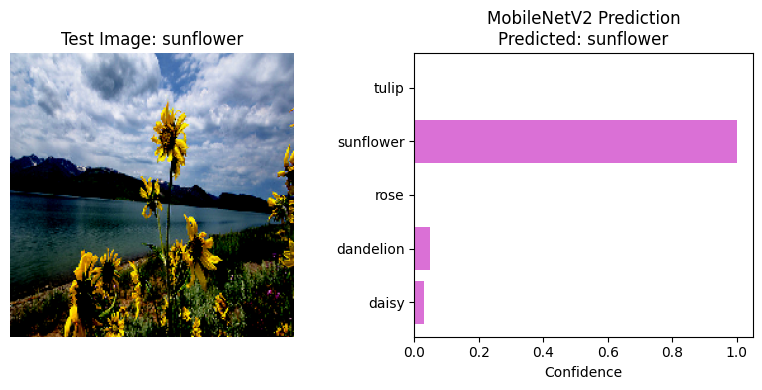

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


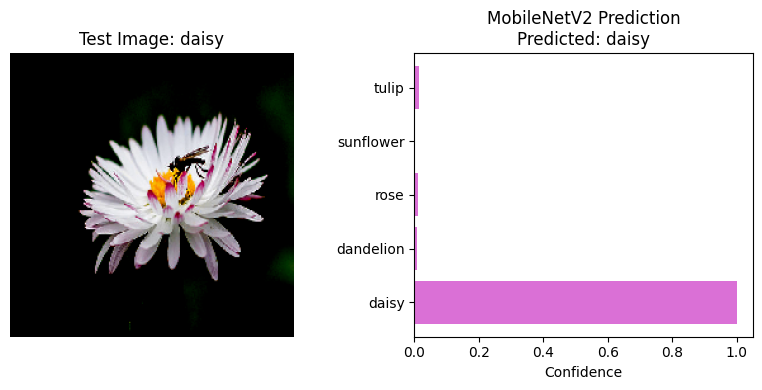

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


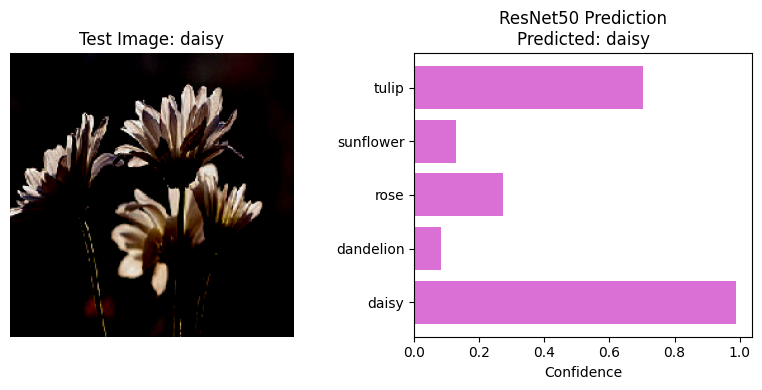

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


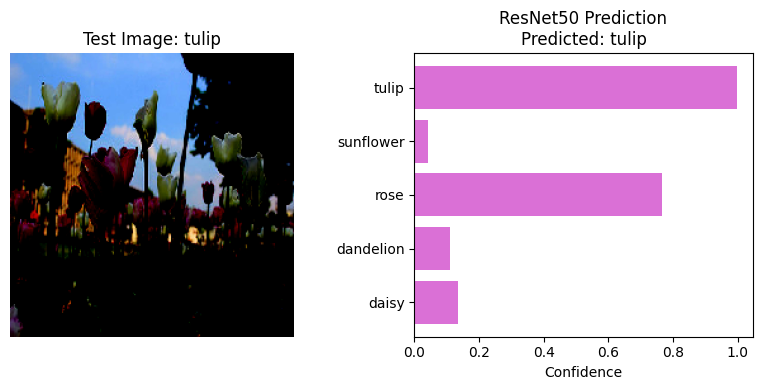

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


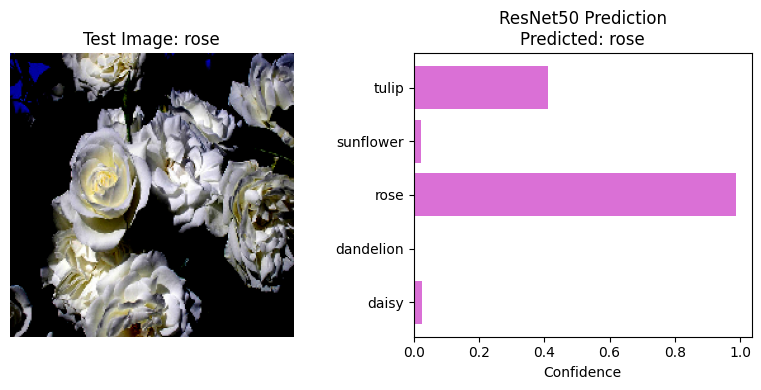

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9607843].


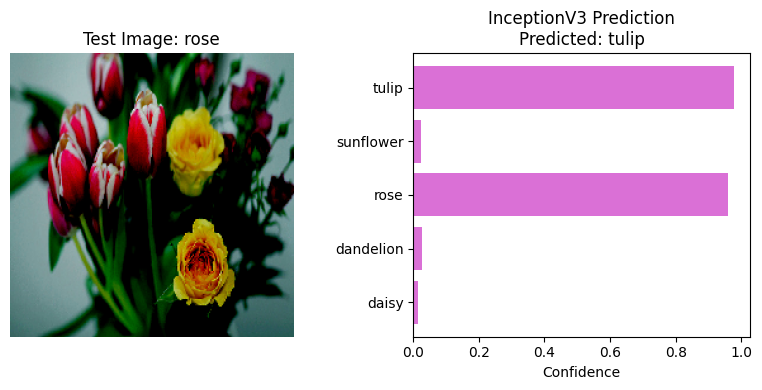

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


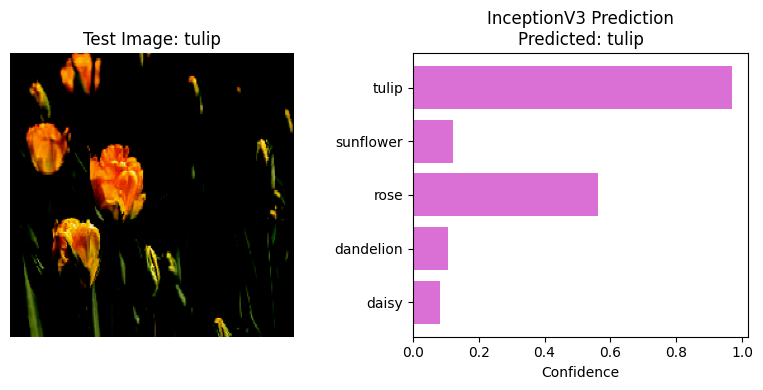

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


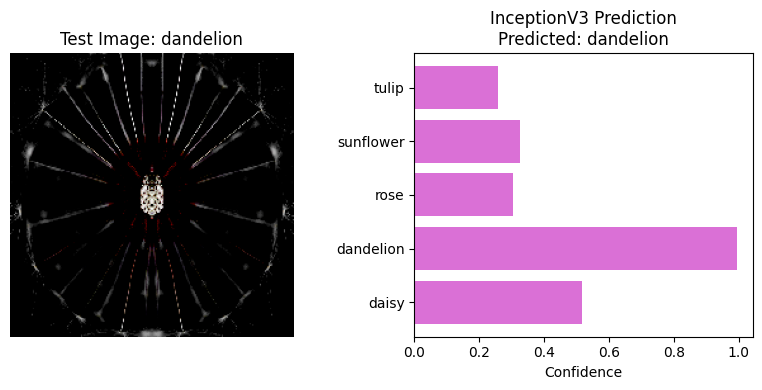

In [ ]:
def plot_prediction_confidences(model, test_images, class_labels, model_name, num_samples=3):
    
    test_images.reset()

    batch_images, batch_labels = next(test_images)
    
    predictions = model.predict(batch_images)

    for i in range(num_samples):
        predicted_class_index = np.argmax(predictions[i])
        true_class_index = np.argmax(batch_labels[i])
        
        predicted_class = list(class_labels.keys())[list(class_labels.values()).index(predicted_class_index)]
        true_class = list(class_labels.keys())[list(class_labels.values()).index(true_class_index)]

        plt.figure(figsize=(8, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(batch_images[i])
        plt.axis('off')
        plt.title(f"Test Image: {true_class}")

        plt.subplot(1, 2, 2)
        plt.barh(list(class_labels.keys()), predictions[i], color='orchid')
        plt.xlabel("Confidence")
        plt.title(f"{model_name} Prediction\nPredicted: {predicted_class}")
        
        plt.tight_layout()
        plt.show()

plot_prediction_confidences(eff_model, test_images, test_images.class_indices, 'EfficientNetB1', num_samples=3)
plot_prediction_confidences(mob_model, test_images, test_images.class_indices, 'MobileNetV2', num_samples=3)
plot_prediction_confidences(resnet_model, test_images, test_images.class_indices, 'ResNet50', num_samples=3)
plot_prediction_confidences(inception_model, test_images, test_images.class_indices, 'InceptionV3', num_samples=3)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

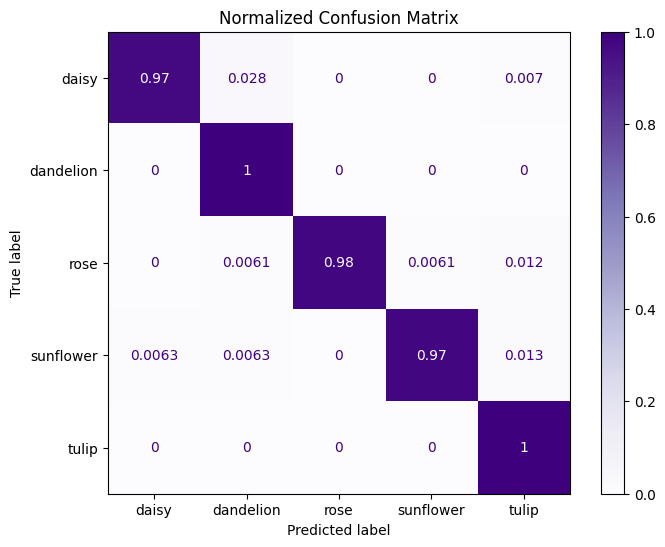

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

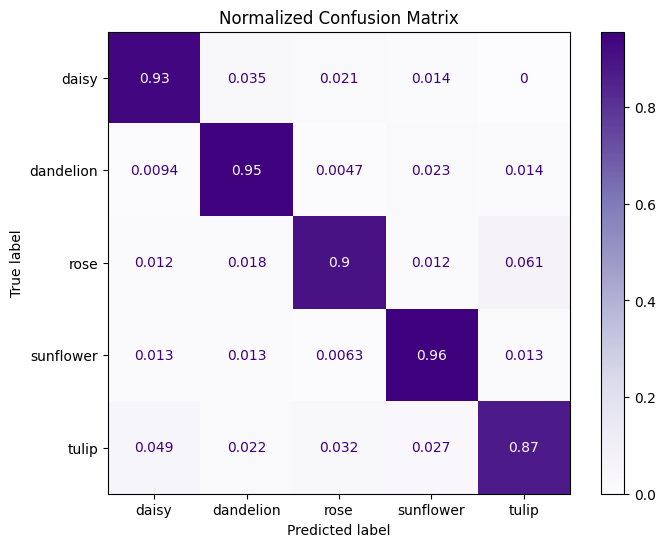

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 459ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 463ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

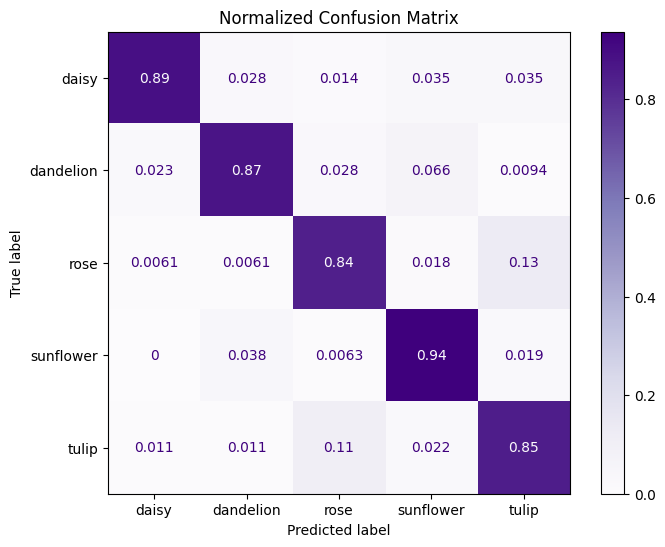

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 441ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

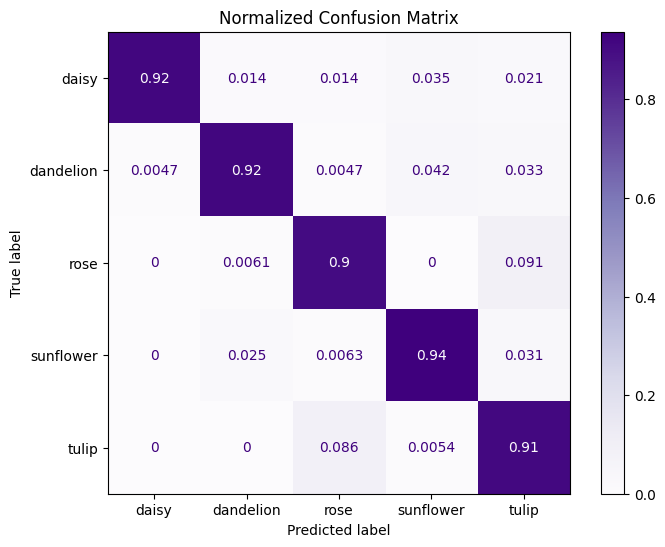

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_matrix(model, test_generator, class_labels):
    test_generator.reset()
    all_preds = []
    all_true = []

    for _ in range(len(test_generator)):
        x_batch, y_batch = next(test_generator)
        preds = model.predict(x_batch)
        all_preds.extend(np.argmax(preds, axis=1))
        all_true.extend(np.argmax(y_batch, axis=1))

    cm = confusion_matrix(all_true, all_preds)
    
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    class_names = list(class_labels.keys())

    disp = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(8, 6))
    disp.plot(ax=ax, cmap='Purples', colorbar=True)
    plt.title("Normalized Confusion Matrix")
    plt.show()

plot_confusion_matrix(eff_model, test_images, test_images.class_indices)
plot_confusion_matrix(mob_model, test_images, test_images.class_indices)
plot_confusion_matrix(resnet_model, test_images, test_images.class_indices)
plot_confusion_matrix(inception_model, test_images, test_images.class_indices)
